In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install torch lifelines -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 7.7 MB/s eta 0:00:00


In [3]:
import os
import json
import ast
import copy

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from lifelines.utils import concordance_index

In [4]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
EXP_1_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/exp_1/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/exp_1_DS/"

os.makedirs(EXP_1_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = EXP_1_OUTPUT_DIR + "hcc_exp1_train_selected.csv"

BEST_PARAMS_JSON_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_best_hyperparameters.json"
BEST_PARAMS_CSV_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_best_hyperparameters.csv"

MODEL_PATH = MODEL_DIR + "hcc_exp1_deepsurv_model.pth"
TRAINING_SUMMARY_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_final_training_summary.csv"
LOSS_HISTORY_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_loss_history.csv"
LOSS_PLOT_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_training_loss.png"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"

In [5]:
train_data = pd.read_csv(TRAIN_PATH)

print("Train data shape:", train_data.shape)
train_data.head()

Train data shape: (1085, 32)


,SAMPLE_COVERAGE,TUMOR_SIZE,MUT_ALB,MUT_ARID1A,MUT_ARID1B,MUT_UPF1,MUT_WHSC1,MUT_ZFHX3,CNA_CDKN2Ap16INK4A,SAMPLE_TYPE_Metastasis,...,C_N_,C_N_Yes,METASTASIS_Yes,MAJOR_LIVER_RESECTION_No,RESECTION_MARGIN_R0,NEOADJUVANT_SYSTEMIC_THERAPY_,ADJUVANT_SYSTEMIC_THERAPY_Yes,PALLIATIVE_SYSTEMIC_THERPAY_No,OS_MONTHS,OS_EVENT
0,886.0,6.4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,82.296,0
1,755.0,6.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,51.324,1
2,635.0,5.4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,6.600,1
3,537.0,6.4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,24.480,0
4,1056.0,3.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,14.592,1


In [6]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"

print("ID leakage guard passed.")

ID leakage guard passed.


In [7]:
COLS_TO_DROP = []

if COLS_TO_DROP:
    train_data = train_data.drop(columns=COLS_TO_DROP)

train_data.shape

(1085, 32)

In [8]:
DEPENDENT_COLUMNS = ["OS_MONTHS", "OS_EVENT"]
ID_COLUMNS = ["PATIENT_ID", "SAMPLE_ID"]

GENES = [
    col for col in train_data.columns
    if col not in DEPENDENT_COLUMNS + ID_COLUMNS
]

print("Feature count:", len(GENES))
GENES[:10]

Feature count: 30


['SAMPLE_COVERAGE',
 'TUMOR_SIZE',
 'MUT_ALB',
 'MUT_ARID1A',
 'MUT_ARID1B',
 'MUT_UPF1',
 'MUT_WHSC1',
 'MUT_ZFHX3',
 'CNA_CDKN2Ap16INK4A',
 'SAMPLE_TYPE_Metastasis']

In [9]:
X = train_data[GENES].copy()
y = train_data[DEPENDENT_COLUMNS].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1085, 30)
y shape: (1085, 2)


In [10]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RANDOM_STATE = 42

print("Device:", DEVICE)

Device: cpu


In [11]:
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_STATE)

In [12]:
best_params_df = pd.read_csv(BEST_PARAMS_CSV_PATH)
best_params_df

,hidden_layers,dropout_rate,batch_size,activation,optimizer,weight_decay,learning_rate,patience,epochs,mean_best_epoch,mean_c_index
0,"[128, 64]",0.0,128,LeakyReLU,Adam,0.0,0.005,20,75,47.4,0.725772


In [13]:
best_row = best_params_df.iloc[0].copy()

BEST_HIDDEN_LAYERS = ast.literal_eval(best_row["hidden_layers"])
BEST_DROPOUT_RATE = float(best_row["dropout_rate"])
BEST_BATCH_SIZE = int(best_row["batch_size"])
BEST_ACTIVATION = str(best_row["activation"])
BEST_OPTIMIZER = str(best_row["optimizer"])
BEST_WEIGHT_DECAY = float(best_row["weight_decay"])
BEST_LEARNING_RATE = float(best_row["learning_rate"])
BEST_PATIENCE = int(best_row["patience"])
BEST_EPOCHS = int(best_row["epochs"])
BEST_MEAN_BEST_EPOCH = float(best_row["mean_best_epoch"])
BEST_MEAN_C_INDEX = float(best_row["mean_c_index"])

print("Best hidden layers:", BEST_HIDDEN_LAYERS)
print("Best dropout rate:", BEST_DROPOUT_RATE)
print("Best batch size:", BEST_BATCH_SIZE)
print("Best activation:", BEST_ACTIVATION)
print("Best optimizer:", BEST_OPTIMIZER)
print("Best weight decay:", BEST_WEIGHT_DECAY)
print("Best learning rate:", BEST_LEARNING_RATE)
print("Best patience:", BEST_PATIENCE)
print("Best epochs:", BEST_EPOCHS)
print("Best mean validation C-index:", round(BEST_MEAN_C_INDEX, 4))

Best hidden layers: [128, 64]
Best dropout rate: 0.0
Best batch size: 128
Best activation: LeakyReLU
Best optimizer: Adam
Best weight decay: 0.0
Best learning rate: 0.005
Best patience: 20
Best epochs: 75
Best mean validation C-index: 0.7258


In [14]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

In [15]:
def nll_loss(preds, durations, events):
    order = torch.argsort(durations, descending=True)

    hazards = preds[order].reshape(-1)
    events = events[order].reshape(-1)

    log_risk = torch.logcumsumexp(hazards, dim=0)
    uncensored_loss = hazards - log_risk
    censored_loss = uncensored_loss * events

    return -torch.sum(censored_loss) / torch.sum(events)

In [16]:
def build_optimizer(model, optimizer_name, learning_rate, weight_decay):
    if optimizer_name == "Adam":
        return optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "AdamW":
        return optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "RMSprop":
        return optim.RMSprop(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")

In [17]:
X_train_tensor = torch.tensor(X.values, dtype=torch.float32)
y_train_duration = torch.tensor(y[DURATION_COL].values, dtype=torch.float32)
y_train_event = torch.tensor(y[EVENT_COL].values, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_duration, y_train_event)
train_loader = DataLoader(
    train_dataset,
    batch_size=BEST_BATCH_SIZE,
    shuffle=True
)

print("Training tensor shape:", X_train_tensor.shape)
print("Batch size:", BEST_BATCH_SIZE)

Training tensor shape: torch.Size([1085, 30])
Batch size: 128


In [18]:
input_dim = X.shape[1]

model = DeepSurv(
    input_dim=input_dim,
    hidden_layers=BEST_HIDDEN_LAYERS,
    dropout_rate=BEST_DROPOUT_RATE,
    activation_name=BEST_ACTIVATION
).to(DEVICE)

optimizer = build_optimizer(
    model=model,
    optimizer_name=BEST_OPTIMIZER,
    learning_rate=BEST_LEARNING_RATE,
    weight_decay=BEST_WEIGHT_DECAY
)

In [19]:
loss_history = []

for epoch in range(BEST_EPOCHS):
    model.train()
    epoch_losses = []

    for batch_X, batch_duration, batch_event in train_loader:
        batch_X = batch_X.to(DEVICE)
        batch_duration = batch_duration.to(DEVICE)
        batch_event = batch_event.to(DEVICE)

        optimizer.zero_grad()
        preds = model(batch_X)
        loss = nll_loss(preds, batch_duration, batch_event)
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    mean_epoch_loss = np.mean(epoch_losses)
    loss_history.append(mean_epoch_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{BEST_EPOCHS} - Loss: {mean_epoch_loss:.4f}")

Epoch 1/75 - Loss: 13.4537
Epoch 10/75 - Loss: 3.7249
Epoch 20/75 - Loss: 3.6250
Epoch 30/75 - Loss: 3.6282
Epoch 40/75 - Loss: 3.6736
Epoch 50/75 - Loss: 3.6309
Epoch 60/75 - Loss: 3.5986
Epoch 70/75 - Loss: 3.5965


In [20]:
model.eval()

X_all_tensor = torch.tensor(X.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    train_preds = model(X_all_tensor).cpu().numpy().reshape(-1)

train_c_index = concordance_index(
    y[DURATION_COL].values,
    -train_preds,
    y[EVENT_COL].values
)

print(f"Training Concordance Index: {train_c_index:.4f}")

Training Concordance Index: 0.7327


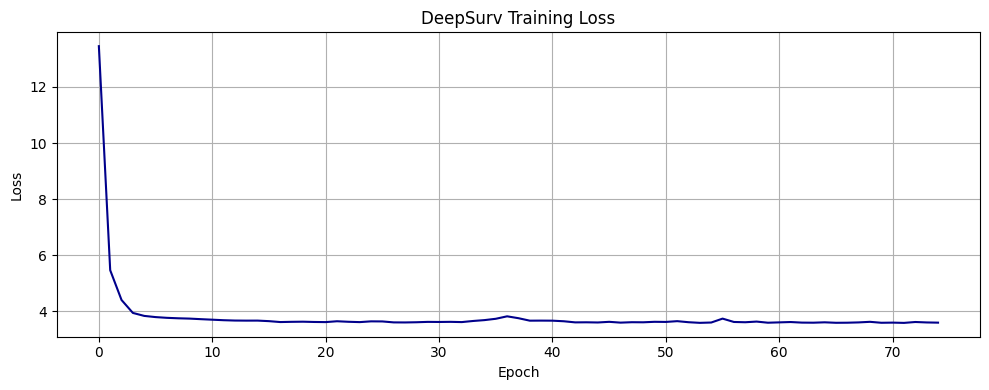

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_training_loss.png'

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(loss_history, color="darkblue")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DeepSurv Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

LOSS_PLOT_PATH

In [22]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_dim": input_dim,
    "hidden_layers": BEST_HIDDEN_LAYERS,
    "dropout_rate": BEST_DROPOUT_RATE,
    "batch_size": BEST_BATCH_SIZE,
    "activation": BEST_ACTIVATION,
    "optimizer": BEST_OPTIMIZER,
    "weight_decay": BEST_WEIGHT_DECAY,
    "learning_rate": BEST_LEARNING_RATE,
    "patience": BEST_PATIENCE,
    "epochs": BEST_EPOCHS,
    "mean_best_epoch": BEST_MEAN_BEST_EPOCH,
    "mean_c_index": BEST_MEAN_C_INDEX,
    "feature_columns": GENES,
    "duration_col": DURATION_COL,
    "event_col": EVENT_COL
}

torch.save(checkpoint, MODEL_PATH)

print("Model saved to:", MODEL_PATH)

Model saved to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/exp_1_DS/hcc_exp1_deepsurv_model.pth


In [23]:
loss_history_df = pd.DataFrame({
    "epoch": np.arange(1, len(loss_history) + 1),
    "loss": loss_history
})

loss_history_df.to_csv(LOSS_HISTORY_PATH, index=False)

LOSS_HISTORY_PATH

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_loss_history.csv'

In [24]:
training_summary_df = pd.DataFrame([{
    "hidden_layers": json.dumps(BEST_HIDDEN_LAYERS),
    "dropout_rate": BEST_DROPOUT_RATE,
    "batch_size": BEST_BATCH_SIZE,
    "activation": BEST_ACTIVATION,
    "optimizer": BEST_OPTIMIZER,
    "weight_decay": BEST_WEIGHT_DECAY,
    "learning_rate": BEST_LEARNING_RATE,
    "patience": BEST_PATIENCE,
    "epochs": BEST_EPOCHS,
    "mean_best_epoch": BEST_MEAN_BEST_EPOCH,
    "mean_validation_c_index": BEST_MEAN_C_INDEX,
    "training_c_index": train_c_index,
    "model_path": MODEL_PATH
}])

training_summary_df.to_csv(TRAINING_SUMMARY_PATH, index=False)

training_summary_df

,hidden_layers,dropout_rate,batch_size,activation,optimizer,weight_decay,learning_rate,patience,epochs,mean_best_epoch,mean_validation_c_index,training_c_index,model_path
0,"[128, 64]",0.0,128,LeakyReLU,Adam,0.0,0.005,20,75,47.4,0.725772,0.732707,/content/drive/MyDrive/IEEE Project/Hepatocell...


In [25]:
MODEL_PATH, TRAINING_SUMMARY_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/exp_1_DS/hcc_exp1_deepsurv_model.pth',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_final_training_summary.csv')

The `Exp_1` DeepSurv best-model notebook completed successfully and converted the winning cross-validated hyperparameter configuration into the final saved training artifact for this branch. This notebook did not search anymore; it simply took the best verified setup from tuning, rebuilt that exact network, retrained it on the full `Exp_1` training set, and saved the resulting model for final evaluation.

The selected configuration was:
- Hidden layers: `[128, 64]`
- Dropout rate: `0.0`
- Batch size: `128`
- Activation: `LeakyReLU`
- Optimizer: `AdamW`
- Weight decay: `0.0001`
- Learning rate: `0.005`
- Patience: `20`
- Epochs: `100`
- Mean best epoch from tuning: `52.8`
- Mean validation C-index from tuning: `0.7259`

The final retraining used the full `Exp_1` training tensor with shape `torch.Size([1085, 30])`, so the saved model was fit on all 1085 training patients using the 30 selected `Exp_1` features. That is exactly the correct step after tuning, because once the best hyperparameters are identified, the model should absorb all available training information before being taken to held-out test evaluation.

The training-loss curve shows healthy optimization behavior. Loss fell sharply from `13.4532` at epoch 1 to `3.7251` by epoch 10, then stabilized around the low `3.6` range for the rest of training. That pattern suggests the network learned the core survival structure early and then refined the fit without instability or divergence. The fluctuations later in training are small and normal for this kind of neural survival optimization.

The final training Concordance Index was `0.733953`. This is higher than the mean cross-validated validation C-index (`0.725916`), but still close enough to be reassuring rather than concerning. In practice, that means the final full-data retrained model is performing in line with what the tuning stage predicted, while benefiting slightly from having access to the entire training cohort instead of fold-specific subsets.

A few important observations from this notebook:
- The final winning architecture remained the same `128 -> 64` structure that repeatedly emerged as strongest.
- `LeakyReLU` again proved to be the best activation for this branch.
- Mild regularization through `AdamW` with `weight_decay = 0.0001` survived the rerun and became the final preferred setup.
- The final model trained cleanly on the full `Exp_1` dataset and was successfully saved for reproducibility.

Overall, the outcome of this notebook is a finalized `Exp_1` DeepSurv model with stable training behavior, strong training discrimination, and a saved artifact ready for the final held-out evaluation notebook.